(891, 12)
(712, 25)
{'max_depth': 3, 'min_samples_split': 2, 'n_estimators': 50}
0.8661499662244175
                         Model  Accuracy  Precision  Recall    F1  ROC-AUC
Logistic Regression (baseline)     0.844      0.825   0.754 0.788    0.879
             Gradient Boosting     0.816      0.810   0.681 0.740    0.856
         Random Forest (tuned)     0.804      0.793   0.667 0.724    0.835
       Random Forest (default)     0.804      0.774   0.696 0.733    0.826
0.8589930618510593 0.018969230981911382
        feature  importance
  cat__Title_Mr    0.211242
  cat__Sex_male    0.192472
cat__Sex_female    0.160583
      num__Fare    0.081692
  cat__Pclass_3    0.071221
 cat__Title_Mrs    0.069393
cat__Title_Miss    0.054781
  cat__Pclass_1    0.030993
       num__Age    0.029973
num__FamilySize    0.029465


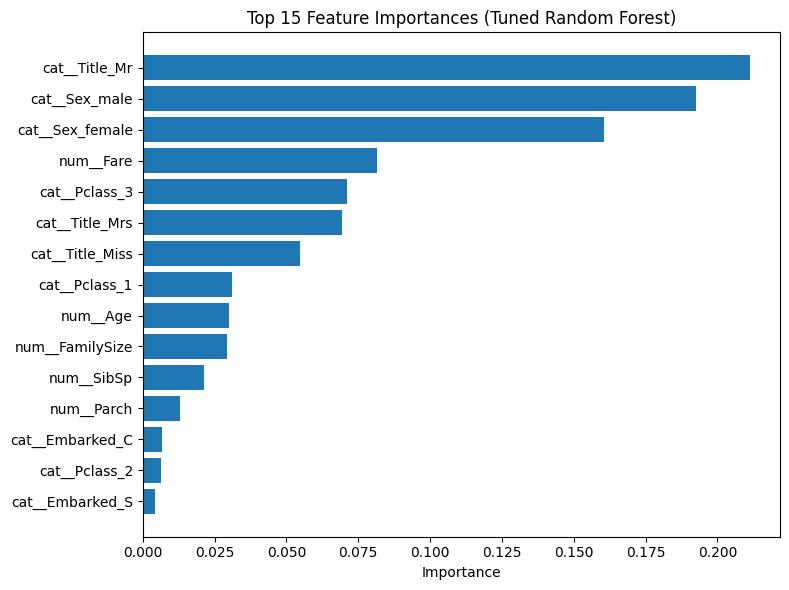

Logistic Regression (baseline) 0.8435754189944135 0.8786561264822135
0.0 0.8786561264822135 0.8786561264822135


In [ ]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import os, urllib.request

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, classification_report)
import joblib

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = "titanic.csv"
DATA_URL = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
if not os.path.exists(DATA_PATH):
    urllib.request.urlretrieve(DATA_URL, DATA_PATH)

df = pd.read_csv(DATA_PATH)
print(df.shape)

df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

df["Title"] = df["Name"].str.extract(r",\s*([^\.]*)\.")
rare_titles = df["Title"].value_counts()[df["Title"].value_counts() < 10].index
df["Title"] = df["Title"].replace(rare_titles, "Rare")
df["Title"] = df["Title"].replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})

df["AgeGroup"] = pd.cut(df["Age"], bins=[0, 12, 18, 35, 60, 100],
                          labels=["Child", "Teen", "Adult", "MiddleAge", "Senior"])

FEATURES = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked",
            "FamilySize", "IsAlone", "Title", "AgeGroup"]
TARGET = "Survived"

X = df[FEATURES].copy()
y = df[TARGET].astype(int)

num_cols = ["Age", "SibSp", "Parch", "Fare", "FamilySize"]
cat_cols = ["Pclass", "Sex", "Embarked", "IsAlone", "Title", "AgeGroup"]

preprocess = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), num_cols),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("ohe", OneHotEncoder(handle_unknown="ignore"))
    ]), cat_cols),
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

X_train_t = preprocess.fit_transform(X_train)
X_test_t = preprocess.transform(X_test)

print(X_train_t.shape)

log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
rf = RandomForestClassifier(random_state=RANDOM_STATE)
gb = GradientBoostingClassifier(random_state=RANDOM_STATE)

log_reg.fit(X_train_t, y_train)
rf.fit(X_train_t, y_train)
gb.fit(X_train_t, y_train)

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [3, 5, 7, None],
    "min_samples_split": [2, 5]
}

grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE),
                     param_grid, cv=5, scoring="roc_auc", n_jobs=-1)
grid.fit(X_train_t, y_train)

print(grid.best_params_)
print(grid.best_score_)

rf_tuned = grid.best_estimator_

def evaluate_model(model, name, X_te, y_te):
    y_pred = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, y_pred),
        "Precision": precision_score(y_te, y_pred),
        "Recall": recall_score(y_te, y_pred),
        "F1": f1_score(y_te, y_pred),
        "ROC-AUC": roc_auc_score(y_te, y_proba)
    }

results = []
results.append(evaluate_model(log_reg, "Logistic Regression (baseline)", X_test_t, y_test))
results.append(evaluate_model(rf, "Random Forest (default)", X_test_t, y_test))
results.append(evaluate_model(gb, "Gradient Boosting", X_test_t, y_test))
results.append(evaluate_model(rf_tuned, "Random Forest (tuned)", X_test_t, y_test))

results_df = pd.DataFrame(results).sort_values("ROC-AUC", ascending=False)
print(results_df.round(3).to_string(index=False))

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
X_full_t = preprocess.transform(X)
cv_scores = cross_val_score(rf_tuned, X_full_t, y, cv=cv, scoring="roc_auc")
print(cv_scores.mean(), cv_scores.std())

feature_names = preprocess.get_feature_names_out()
importances = rf_tuned.feature_importances_
importance_df = pd.DataFrame({
    "feature": feature_names,
    "importance": importances
}).sort_values("importance", ascending=False)

print(importance_df.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 6))
top15 = importance_df.head(15).sort_values("importance")
ax.barh(top15["feature"], top15["importance"])
ax.set_title("Top 15 Feature Importances (Tuned Random Forest)")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

best_row = results_df.iloc[0]
print(best_row["Model"], best_row["Accuracy"], best_row["ROC-AUC"])

final_pipeline = Pipeline([
    ("prep", preprocess),
    ("clf", rf_tuned)
])
final_pipeline.fit(X_train, y_train)

joblib.dump(final_pipeline, "model_task6.joblib")

baseline_auc = results_df[results_df["Model"] == "Logistic Regression (baseline)"]["ROC-AUC"].values[0]
best_auc = best_row["ROC-AUC"]
print(best_auc - baseline_auc, baseline_auc, best_auc)